In [1]:
import pandas as pd
df=pd.read_excel(r"C:\Users\arthur.zhao\Downloads\测试数据-4.22.xlsx")
df1=df.dropna()#删除含有缺失值的行
#data=df1.drop('PN500',axis=1) 删除单列
#data=df1.drop(columns=['PN500','工单号','SN','测试机台','EvbNo','FiberNo','参数类型','测试时间','温度'])
# 筛选 CabinetName 列精确等于 "PSMB ATS114 SM" 的行
df_filtered = df[(df['StartTime'] >= '2024/12/26') & 
                 (df['StartTime'] <= '2025/1/17') & (df['WorkOrder']=='WOOBYS15')]
data=df_filtered[['RxRSP(A/W)','StartTime']]
data

,RxRSP(A/W),StartTime
0,0.701817,2024-12-27
1,0.677305,2024-12-27
2,0.678595,2024-12-27
3,0.701817,2024-12-27
4,0.732779,2024-12-27
...,...,...
580459,0.603769,2024-12-26
580460,0.638602,2024-12-26
580461,0.699237,2024-12-26
580462,0.657953,2024-12-26


In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import Birch
from sklearn.cluster import DBSCAN
from sklearn.cluster import OPTICS
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler
import optuna
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import normalized_mutual_info_score

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

In [3]:
arr=np.array(data) 
#将数据变为数组

In [4]:
#数据标准化
z_scaler=StandardScaler()
data_z=z_scaler.fit_transform(data)
data_z=pd.DataFrame(data_z)


DTypePromotionError: The DType <class 'numpy.dtypes.Float64DType'> could not be promoted by <class 'numpy.dtypes.DateTime64DType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.DateTime64DType'>)

In [ ]:
#data_list=df['测试值'].tolist()
#arr1=np.array(data_list)
#arr1  选取一个列作为新的数组

In [ ]:
#selected_columns=df.iloc[:,[7,9]] 选取的两个列（对应大的中括号里的第二位）（7，9对应列数）
#new_array=selected_columns.values
#new_array 

## DBSCAN scatter

In [9]:
#db=DBSCAN(eps=0.3,min_samples=10)
#db.fit(data)

db = DBSCAN(eps=0.29, min_samples=6)

labels = db.fit_predict(data[['RxRSP(A/W)']])
data.loc[:, 'cluster'] = labels #基于标签的索引器，索引器是pandas中用于安全地访问和修改DataFrame或Series数据的特殊方法。
#DBSCAN不需要两组数据，但强调二维数组，因此data里面需要用两个括号
#fit_predict()：同时进行拟合和预测，返回每个点的簇标签
#labels：包含每个点的簇ID（-1表示噪声点）
# 然后用无意义的数据做可视化（X轴）
plt.figure(figsize=(20, 20))
scatter = plt.scatter(data['StartTime'], 
                     data['RxRSP(A/W)'], 
                     c=data['cluster'], 
                     cmap='tab10',
                     s=50)
plt.xlabel('StartTime')
plt.ylabel('RxRSP(A/W)')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, alpha=0.3)
plt.savefig('scatter.png',bbox_inches='tight')
plt.show()

MemoryError: 

## DBSCAN boxplot

<Figure size 1400x600 with 0 Axes>

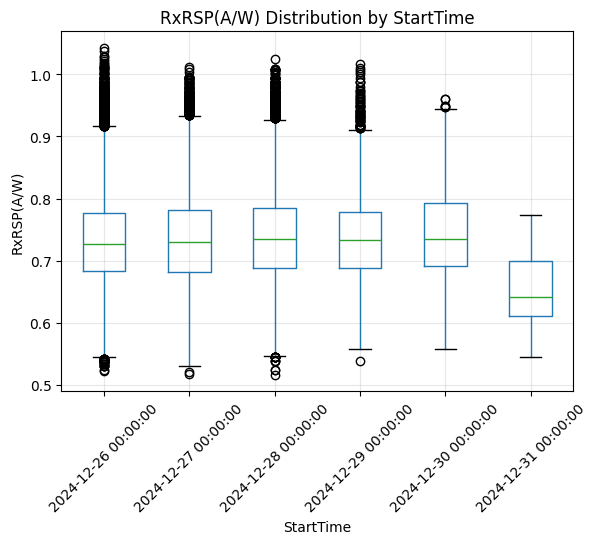

In [6]:
plt.figure(figsize=(14, 6))
data.boxplot(column='RxRSP(A/W)', by='StartTime')
plt.xlabel('StartTime')
plt.ylabel('RxRSP(A/W)')
plt.title('RxRSP(A/W) Distribution by StartTime')
plt.suptitle('')  # 移除默认标题
plt.xticks(rotation=45)  # 旋转X轴标签避免重叠
plt.grid(True, alpha=0.3)
plt.savefig('boxplot.png',bbox_inches='tight')
#总是先 savefig() 再 show()，因为 show() 后会清空图形缓冲区。
plt.show()

## Optics

C:\Users\arthur.zhao\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_optics.py:1084: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]
C:\Users\arthur.zhao\AppData\Local\Temp\ipykernel_12620\460950610.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, 'optics_cluster'] = labels  #创建该列


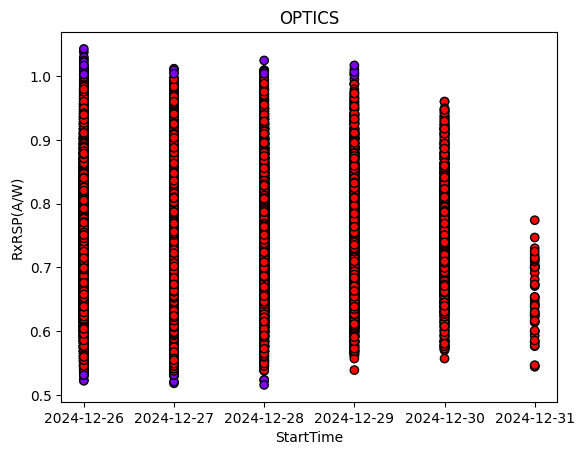

In [3]:
X = data[['RxRSP(A/W)']].values
clustering = OPTICS(min_samples=20, xi=0.33, min_cluster_size=0.2)
clustering.fit(X)
labels = clustering.labels_
data.loc[:, 'optics_cluster'] = labels  #创建该列
plt.scatter(data['StartTime'], data['RxRSP(A/W)'], 
           c=data['optics_cluster'], cmap='rainbow', edgecolor='k')
plt.title("OPTICS")
plt.xlabel("StartTime")
plt.ylabel("RxRSP(A/W)")
plt.savefig('Optics.png',bbox_inches='tight')
plt.show()

In [ ]:
# 简单箱线图版本
# 简化版Reachability Plot
plt.figure(figsize=(12, 6))

# 获取排序后的reachability距离
ordering = clustering.ordering_
reachability = clustering.reachability_[ordering]
labels = clustering.labels_[ordering]

# 创建颜色映射
unique_labels = set(labels)
color_map = {}
for i, label in enumerate(unique_labels):
    if label == -1:
        color_map[label] = 'black'
    else:
        color_map[label] = plt.cm.rainbow(i / len(unique_labels))

# 绘制每个点
for i in range(len(ordering)):
    plt.plot(i, reachability[i], 'o', 
             color=color_map[labels[i]], 
             markersize=5, 
             alpha=0.7)

plt.xlabel('Ordered Points')
plt.ylabel('Reachability Distance')
plt.title('OPTICS Reachability Plot')
plt.grid(True, alpha=0.3)

# 添加图例
from matplotlib.lines import Line2D
legend_elements = []
for label in sorted(unique_labels):
    if label == -1:
        legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                    markerfacecolor='black', markersize=8, label='Noise'))
    else:
        legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                    markerfacecolor=color_map[label], markersize=8, 
                                    label=f'Cluster {label}'))

plt.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

In [11]:
#获取聚类标签
labels=db.labels_
labels

array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [12]:
#计算轮廓系数
score=silhouette_score(data,labels)
print('轮廓系数：',score)

轮廓系数： 0.3230775313833887


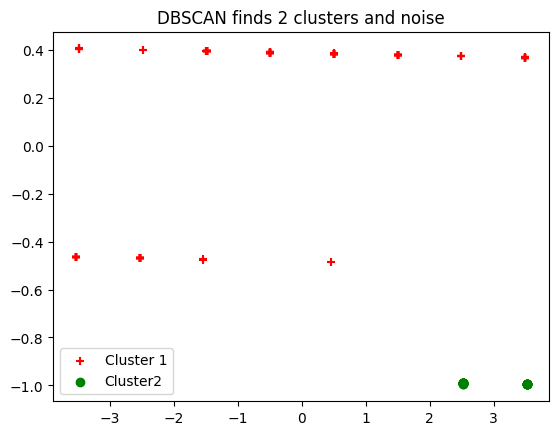

In [13]:
pca= PCA(n_components=2).fit(data)
pca_2d=pca.transform(data)
#为了可视化。通过PCA将数据降到二维
#可视化结果：
for i in range(0, pca_2d.shape[0]):
    if db.labels_[i]==0:
        c1=plt.scatter(pca_2d[i,0],pca_2d[i,1],c='r',marker='+')
    elif db.labels_[i]==1:
        c2=plt.scatter(pca_2d[i,0],pca_2d[i,1],c='g',marker='o')
   # elif db.labels_[i]==2:
    #    c3=plt.scatter(pca_2d[i,0],pca_2d[i,1],c='b',marker='*')
#elif db.labels_[i]==-1:
   #     c4=plt.scatter(pca_2d[i,0],pca_2d[i,1],c='k',marker='x')

plt.legend([c1,c2],['Cluster 1','Cluster2'])
plt.title('DBSCAN finds 2 clusters and noise')
plt.show()


In [31]:
# 分别处理数值和日期数据
rssp_array = data['RxRSP(A/W)'].values  # 浮点数数组
time_array = data['StartTime'].values    # 日期时间数组

print("光功率数组:", rssp_array.shape, rssp_array.dtype)
print("时间数组:", time_array.shape, time_array.dtype)

光功率数组: (7008,) float64
时间数组: (7008,) datetime64[ns]


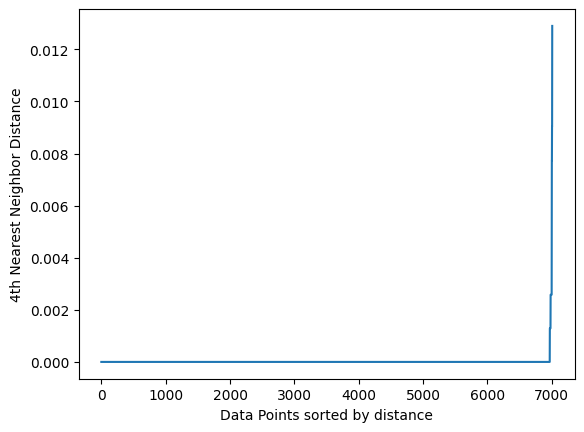

In [36]:
neigh=NearestNeighbors(n_neighbors=4)
nbrs=neigh.fit(data2)
distances, indices=nbrs.kneighbors(data2)

distances=np.sort(distances[:,3],axis=0)
#distances = distances[:,1]
plt.plot(distances)
plt.xlabel('Data Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.show()